# EDA de IEEE-CIS Fraud Detection

Este análisis busca conocer el tercer dataset del proyecto
antes de construir los contextos de TabPFN.

Trabajamos únicamente con train de la semilla 0.
Validación y test quedan reservados para los experimentos.

Analizamos:
1. Balance de clases y contextos esperados.
2. Tipos de columnas y valores faltantes.
3. Información de identidad.
4. Montos y tiempos de transacción.
5. Variables categóricas.
6. Señal de variables numéricas.
7. Duplicados.

In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml
from IPython.display import display
from sklearn.metrics import roc_auc_score

from tpf.contexts.expected import expected_context_positives
from tpf.data.loaders import load_ieee_cis
from tpf.data.splits import load_split, row_hashes, split_path
from tpf.paths import CONFIGS, DATA_SPLITS, REPORTS

SEED = 0
FIG_DIR = REPORTS / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

cfg = yaml.safe_load((CONFIGS / "default.yaml").read_text(encoding="utf-8"))
TAMANIOS = cfg["context"]["sizes"]
ESTRATEGIAS = cfg["context"]["strategies"]

pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
pd.set_option("display.max_columns", 30)
plt.rcParams["figure.dpi"] = 110

COLORES = {"legítima": "tab:blue", "fraude": "tab:red"}

## 0. Preparación y carga de train.

In [2]:
X_all, y_all = load_ieee_cis()

if not split_path("ieee_cis", SEED).exists():
    raise FileNotFoundError(
        "Primero ejecutar: python scripts/01_make_splits.py --datasets ieee_cis"
    )

parts = load_split("ieee_cis", SEED)

idx_train = parts["train"]
X = X_all.iloc[idx_train].reset_index(drop=True)
y = y_all.iloc[idx_train].reset_index(drop=True)

etiqueta = y.map({0: "legítima", 1: "fraude"})

del X_all, y_all, parts

assert X.shape == (354_324, 432), X.shape
assert 0 < int(y.sum()) < len(y)

print(f"Train (semilla {SEED}): {X.shape[0]:,} filas x {X.shape[1]} columnas")
print(f"Fraudes: {int(y.sum()):,}")
print(f"Memoria de X: {X.memory_usage(deep=True).sum() / 2**20:,.1f} MiB")

Train (semilla 0): 354,324 filas x 432 columnas
Fraudes: 12,398
Memoria de X: 1,185.2 MiB


## 1. Balance de clases.

,filas,porcentaje
legítima (0),341926,96.501
fraude (1),12398,3.499


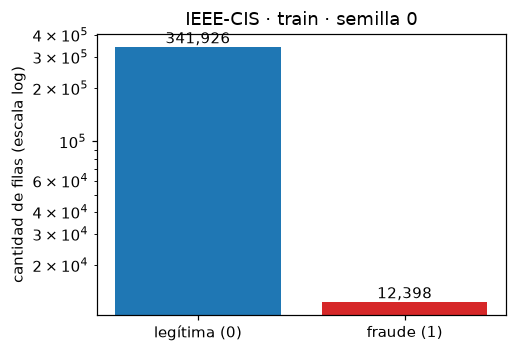

In [3]:
n = len(y)
n_pos = int(y.sum())
n_neg = n - n_pos
pi = n_pos / n

balance = pd.DataFrame(
    {
        "filas": [n_neg, n_pos],
        "porcentaje": [100 * n_neg / n, 100 * pi],
    },
    index=["legítima (0)", "fraude (1)"],
)

display(balance)

fig, ax = plt.subplots(figsize=(4.8, 3.3))
valores = [n_neg, n_pos]

ax.bar(
    ["legítima (0)", "fraude (1)"],
    valores,
    color=[COLORES["legítima"], COLORES["fraude"]],
)
ax.set_yscale("log")
ax.set_ylabel("cantidad de filas (escala log)")
ax.set_title(f"IEEE-CIS · train · semilla {SEED}")

for i, v in enumerate(valores):
    ax.text(i, v, f"{v:,}", ha="center", va="bottom")

fig.tight_layout()
fig.savefig(FIG_DIR / "06_eda_ieee_balance.png")
plt.show()

### ¿Cuántos fraudes entran en un contexto?.

In [4]:
filas = []

for m in TAMANIOS:
    for estrategia in ESTRATEGIAS:
        r = expected_context_positives(n, n_pos, m, estrategia)

        filas.append(
            {
                "m": m,
                "estrategia": estrategia,
                "fraudes esperados": r.n_pos,
                "pi_ctx (%)": 100 * r.pi_ctx,
                "P(0 fraudes) (%)": (100 * r.p_zero_pos if estrategia == "uniform" else np.nan),
                "capado": "sí" if r.capped else "no",
            }
        )

tabla_contextos = pd.DataFrame(filas)
display(tabla_contextos)

,m,estrategia,fraudes esperados,pi_ctx (%),P(0 fraudes) (%),capado
0,1000,uniform,34.991,3.499,0.000,no
1,1000,stratified,35.000,3.500,NaN,no
2,1000,balanced,500.000,50.000,NaN,no
3,1000,nearmiss,500.000,50.000,NaN,no
4,1000,iht,500.000,50.000,NaN,no
5,5000,uniform,174.953,3.499,0.000,no
6,5000,stratified,175.000,3.500,NaN,no
7,5000,balanced,"2,500.000",50.000,NaN,no
8,5000,nearmiss,"2,500.000",50.000,NaN,no
9,5000,iht,"2,500.000",50.000,NaN,no


## 2. Tipos de columnas y valores faltantes.

Columnas numéricas: 401
Columnas categóricas según su tipo: 31
Categóricas: ['ProductCD', 'card4', 'card6', 'P_emaildomain', 'R_emaildomain', 'M1', 'M2', 'M3', 'M4', 'M5', 'M6', 'M7', 'M8', 'M9', 'id_12', 'id_15', 'id_16', 'id_23', 'id_27', 'id_28', 'id_29', 'id_30', 'id_31', 'id_33', 'id_34', 'id_35', 'id_36', 'id_37', 'id_38', 'DeviceType', 'DeviceInfo']

Columnas con algún faltante: 414
Columnas con más de 50% de faltantes: 214
Columnas con más de 90% de faltantes: 12
Filas con algún faltante: 100.00%


,% faltante
id_24,99.192
id_25,99.127
id_07,99.123
id_08,99.123
id_26,99.122
id_21,99.122
id_23,99.121
id_27,99.121
id_22,99.121
dist2,93.685


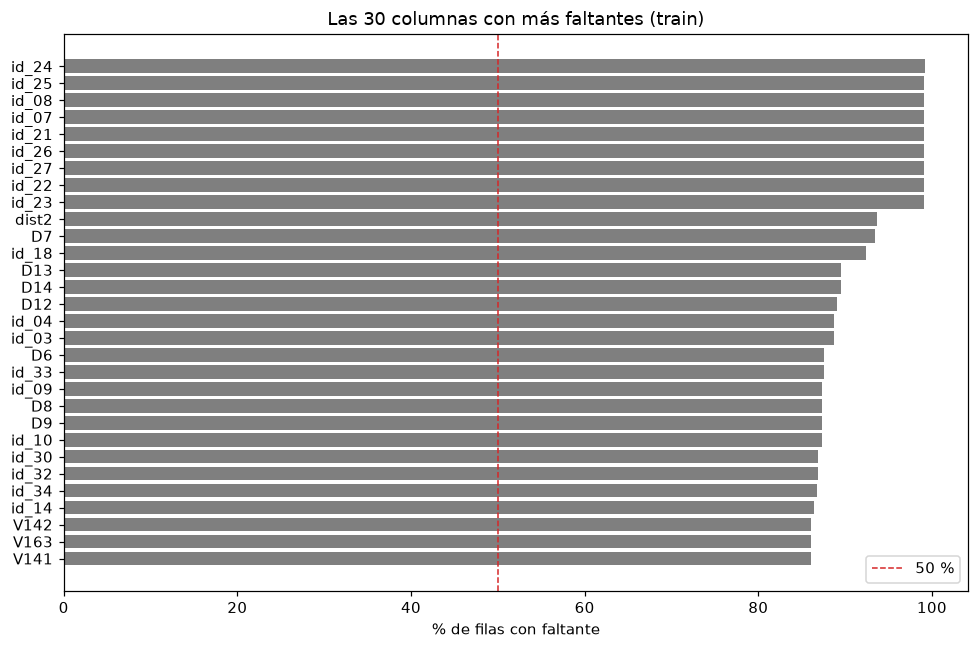

In [6]:
cols_num = X.select_dtypes(include="number").columns.tolist()
cols_cat = X.select_dtypes(exclude="number").columns.tolist()

print(f"Columnas numéricas: {len(cols_num)}")
print(f"Columnas categóricas según su tipo: {len(cols_cat)}")
print("Categóricas:", cols_cat)

pct_na = X.isna().mean().mul(100).sort_values(ascending=False)

print(f"\nColumnas con algún faltante: {int((pct_na > 0).sum())}")
print(f"Columnas con más de 50% de faltantes: {int((pct_na > 50).sum())}")
print(f"Columnas con más de 90% de faltantes: {int((pct_na > 90).sum())}")
print(f"Filas con algún faltante: {100 * X.isna().any(axis=1).mean():.2f}%")

display(pct_na.head(20).to_frame("% faltante"))

top = pct_na.head(30).sort_values()

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(top.index, top.values, color="tab:gray")
ax.axvline(50, color="tab:red", ls="--", lw=1, label="50 %")
ax.set_xlabel("% de filas con faltante")
ax.set_title("Las 30 columnas con más faltantes (train)")
ax.legend()

fig.tight_layout()
fig.savefig(FIG_DIR / "06_eda_ieee_faltantes.png")
plt.show()

## 3. Información de identidad

In [7]:
cols_identity = [c for c in X.columns if c.startswith("id_") or c in ("DeviceType", "DeviceInfo")]

tiene_datos_identidad = X[cols_identity].notna().any(axis=1)

tabla_identidad = y.groupby(tiene_datos_identidad).agg(
    transacciones="size",
    fraudes="sum",
    tasa_fraude="mean",
)
tabla_identidad["tasa_fraude"] *= 100

tabla_identidad.index = tabla_identidad.index.map(
    {False: "sin datos de identidad", True: "con datos de identidad"}
)

display(tabla_identidad)

print(
    f"Transacciones con alguna característica de identidad: "
    f"{100 * tiene_datos_identidad.mean():.2f}%"
)

,transacciones,fraudes,tasa_fraude
sin datos de identidad,267778,5598,2.091
con datos de identidad,86546,6800,7.857


Transacciones con alguna característica de identidad: 24.43%


## 4. Monto y tiempo de las transacciones.

TransactionAmt:


,count,mean,std,min,50%,90%,99%,max
isFraud,,,,,,,,
fraude,"12,398.000",150.557,241.165,0.292,75.000,335.000,994.000,"5,191.000"
legítima,"341,926.000",135.032,246.467,0.251,68.500,269.945,"1,104.000","31,937.391"


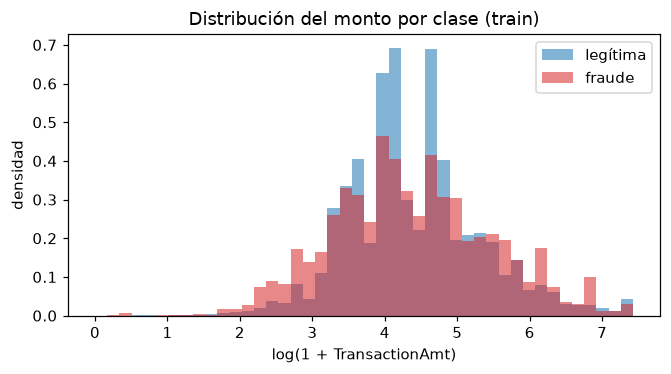

In [8]:
print("TransactionAmt:")
display(X.groupby(etiqueta)["TransactionAmt"].describe(percentiles=[0.5, 0.9, 0.99]))

log_amount = np.log1p(X["TransactionAmt"].clip(lower=0))
bins = np.linspace(0, log_amount.quantile(0.995), 45)

fig, ax = plt.subplots(figsize=(6.2, 3.5))

for clase, color in COLORES.items():
    valores = log_amount[etiqueta == clase].dropna()
    ax.hist(
        valores.clip(upper=bins[-1]),
        bins=bins,
        density=True,
        alpha=0.55,
        color=color,
        label=clase,
    )

ax.set_xlabel("log(1 + TransactionAmt)")
ax.set_ylabel("densidad")
ax.set_title("Distribución del monto por clase (train)")
ax.legend()

fig.tight_layout()
fig.savefig(FIG_DIR / "06_eda_ieee_amount.png")
plt.show()

TransactionDT: desde 1.0 hasta 183.0 días


,transacciones,fraudes,tasa_fraude
TransactionDT,,,
"(0.819, 16.167]",37428,1014,2.709
"(16.167, 31.334]",43976,1102,2.506
"(31.334, 46.5]",28041,1062,3.787
"(46.5, 61.667]",25936,1074,4.141
"(61.667, 76.833]",28975,1246,4.300
"(76.833, 92.0]",27711,1044,3.767
"(92.0, 107.166]",31623,1085,3.431
"(107.166, 122.333]",27408,1250,4.561
"(122.333, 137.499]",26112,864,3.309


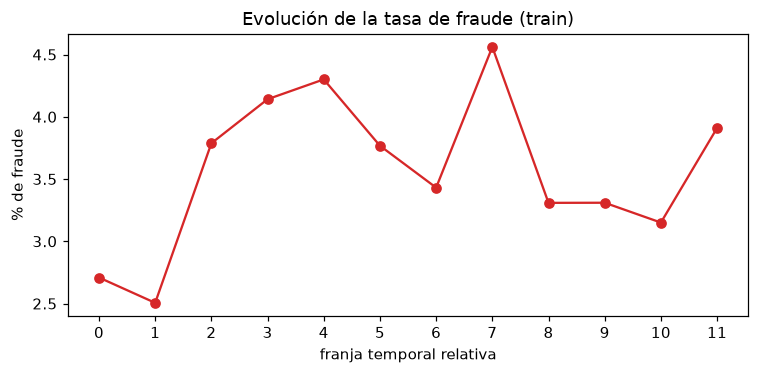

In [9]:
dias = X["TransactionDT"] / (3600 * 24)

print(f"TransactionDT: desde {dias.min():.1f} hasta {dias.max():.1f} días")

franjas = pd.cut(dias, bins=12)
tabla_tiempo = y.groupby(franjas, observed=False).agg(
    transacciones="size",
    fraudes="sum",
    tasa_fraude="mean",
)
tabla_tiempo["tasa_fraude"] *= 100

display(tabla_tiempo)

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(
    range(len(tabla_tiempo)),
    tabla_tiempo["tasa_fraude"],
    marker="o",
    color="tab:red",
)

ax.set_xlabel("franja temporal relativa")
ax.set_ylabel("% de fraude")
ax.set_title("Evolución de la tasa de fraude (train)")
ax.set_xticks(range(len(tabla_tiempo)))

fig.tight_layout()
fig.savefig(FIG_DIR / "06_eda_ieee_time.png")
plt.show()

## 5. Variables categóricas.

In [10]:
card = pd.DataFrame(
    {
        "categorías distintas": X[cols_cat].nunique(dropna=True),
        "% faltante": pct_na[cols_cat],
    }
).sort_values("categorías distintas", ascending=False)

display(card.head(25))

ancho_onehot = int(sum(X[c].nunique(dropna=False) for c in cols_cat))

print(f"Ancho estimado de one-hot para las categóricas detectadas: {ancho_onehot} columnas")

for c in ("ProductCD", "card4", "P_emaildomain", "DeviceType"):
    grupos = X[c].fillna("FALTANTE")

    tabla = y.groupby(grupos).agg(
        transacciones="size",
        fraudes="sum",
        tasa_fraude="mean",
    )
    tabla["tasa_fraude"] *= 100

    print(f"\n{c}:")
    display(tabla.sort_values("transacciones", ascending=False).head(12))

,categorías distintas,% faltante
DeviceInfo,1574,79.887
id_33,222,87.563
id_31,124,76.248
id_30,75,86.838
R_emaildomain,60,76.772
P_emaildomain,59,15.964
ProductCD,5,0.000
card6,4,0.265
card4,4,0.267
id_34,4,86.800


Ancho estimado de one-hot para las categóricas detectadas: 2206 columnas

ProductCD:


,transacciones,fraudes,tasa_fraude
ProductCD,,,
W,263747,5369,2.036
C,41048,4826,11.757
R,22665,837,3.693
H,19892,965,4.851
S,6972,401,5.752



card4:


,transacciones,fraudes,tasa_fraude
card4,,,
visa,231078,8043,3.481
mastercard,113256,3875,3.421
american express,4988,147,2.947
discover,4056,306,7.544
FALTANTE,946,27,2.854



P_emaildomain:


,transacciones,fraudes,tasa_fraude
P_emaildomain,,,
gmail.com,137167,5986,4.364
yahoo.com,60642,1411,2.327
FALTANTE,56563,1644,2.906
hotmail.com,27045,1407,5.202
anonymous.com,22187,548,2.470
aol.com,17047,372,2.182
comcast.net,4747,139,2.928
icloud.com,3801,123,3.236
outlook.com,3058,287,9.385



DeviceType:


,transacciones,fraudes,tasa_fraude
DeviceType,,,
FALTANTE,269846,5661,2.098
desktop,51105,3358,6.571
mobile,33373,3379,10.125


## 6. Señal individual de las variables.

,AUC (1 variable),% de filas con dato,"distancia a 0,5"
D5,0.253,47.540,0.247
D2,0.296,52.367,0.204
D3,0.300,55.433,0.200
C4,0.688,100.000,0.188
D8,0.315,12.703,0.185
C8,0.683,100.000,0.183
C10,0.677,100.000,0.177
V16,0.664,87.094,0.164
V15,0.664,87.094,0.164
C12,0.664,100.000,0.164


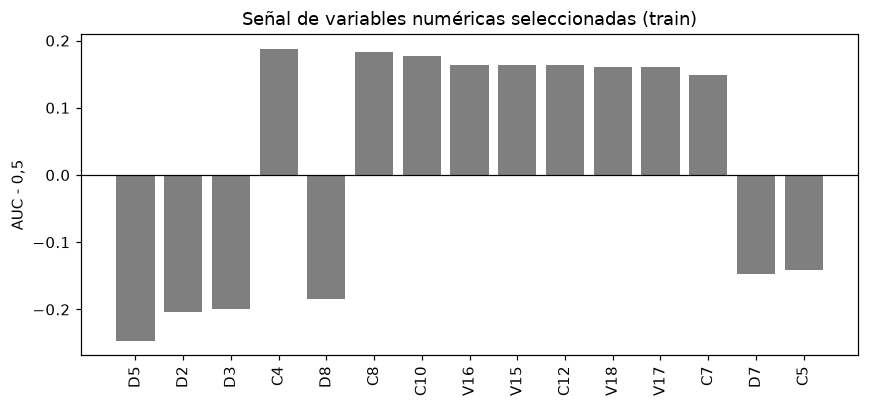

In [11]:
# Seleccionamos variables representativas para no recorrer todas las V.
candidatas = (
    ["TransactionAmt", "TransactionDT"]
    + [f"C{i}" for i in range(1, 15)]
    + [f"D{i}" for i in range(1, 16)]
    + [f"V{i}" for i in range(1, 21)]
)

candidatas = [c for c in candidatas if c in X.columns]

auc_uni = {}
cobertura = {}

for c in candidatas:
    ok = X[c].notna() & np.isfinite(X[c])

    if ok.sum() < 1_000 or X.loc[ok, c].nunique() < 2:
        continue

    if y[ok].nunique() < 2:
        continue

    auc_uni[c] = roc_auc_score(y[ok], X.loc[ok, c])
    cobertura[c] = 100 * ok.mean()

senal = pd.DataFrame(
    {
        "AUC (1 variable)": pd.Series(auc_uni),
        "% de filas con dato": pd.Series(cobertura),
    }
)

senal["distancia a 0,5"] = (senal["AUC (1 variable)"] - 0.5).abs()
senal = senal.sort_values("distancia a 0,5", ascending=False)

display(senal.head(15))

top15 = senal.head(15)

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.bar(
    top15.index,
    top15["AUC (1 variable)"] - 0.5,
    color="tab:gray",
)
ax.axhline(0, color="black", lw=0.8)
ax.set_ylabel("AUC - 0,5")
ax.set_title("Señal de variables numéricas seleccionadas (train)")
ax.tick_params(axis="x", rotation=90)

fig.tight_layout()
fig.savefig(FIG_DIR / "06_eda_ieee_auc.png")
plt.show()

## 7. Duplicados y auditoría

In [12]:
h = row_hashes(X)
duplicadas = pd.Series(h).duplicated(keep="first")

n_dup = int(duplicadas.sum())
n_dup_pos = int(y[duplicadas].sum())

print(f"Filas repetidas en train: {n_dup:,}")
print(f"Porcentaje de train: {100 * n_dup / len(y):.3f}%")
print(f"Fraudes entre las filas repetidas: {n_dup_pos}")

# Buscamos posibles filas idénticas con etiquetas diferentes.
grupos = pd.DataFrame({"hash": h, "y": y}).groupby("hash")["y"].nunique()
conflictos = int((grupos > 1).sum())

print(f"Grupos con etiquetas contradictorias: {conflictos}")

# Consultamos la auditoría global ya generada por el script de splits.
ruta_manifest = DATA_SPLITS / "MANIFEST_splits.json"

if ruta_manifest.exists():
    manifiesto = json.loads(ruta_manifest.read_text(encoding="utf-8"))
    info = manifiesto["datasets"].get("ieee_cis")

    if info is not None:
        print("\nDuplicados globales:", info["dup_global"])
        print(
            f"Duplicados cruzados seed {SEED}:",
            info["by_seed"][str(SEED)]["dup_cross"],
        )

Filas repetidas en train: 2
Porcentaje de train: 0.001%
Fraudes entre las filas repetidas: 0
Grupos con etiquetas contradictorias: 0

Duplicados globales: {'n_dup_rows': 3, 'n_dup_pos': 0}
Duplicados cruzados seed 0: {'val': 1, 'test': 0}
